In [1]:
import math
from dataclasses import dataclass
from functools import cache, partial

import numpy as np
import pandas as pd
import seaborn as sns
import sympy as sp
import matplotlib.pyplot as plt


L_x, R_x = 0, math.pi / 2
L_y, R_y = 0, math.pi / 2

a = 0
b = 0
c = 2

n = 40
m = 40
eps = 1e-12

**Вариант 7**

$
\begin{cases}
\dfrac{\partial^2 u}{\partial x^2} + \dfrac{\partial^2 u}{\partial y^2} = -2u, \quad 0 < x < \dfrac{\pi}{2},\ 0 < y < \dfrac{\pi}{2}, \\
u(0, y) = \cos y, \\
u\left(\dfrac{\pi}{2}, y\right) = 0, \\
u(x, 0) = \cos x, \\
u\left(x, \dfrac{\pi}{2}\right) = 0,
\end{cases}
\qquad
U(x, y) = \cos x\cos y
$

Общая постановка - стационарное двумерное уравнение эллиптического типа в прямоугольнике $[L_x, R_x] \times [L_y, R_y]$ с граничными условиями первого рода:

$
\dfrac{\partial^2 u}{\partial x^2} + \dfrac{\partial^2 u}{\partial y^2} + a\dfrac{\partial u}{\partial x} + b\dfrac{\partial u}{\partial y} + cu + f(x, y) = 0,
$

$
u(x, L_y) = \varphi_L(x), \qquad u(x, R_y) = \varphi_R(x), \qquad u(L_x, y) = \psi_L(y), \qquad u(R_x, y) = \psi_R(y).
$

При $a = b = c = 0$ это задача Дирихле для уравнения Пуассона (функция $f$ здесь берётся с обратным знаком).

$a = 0$, $b = 0$, $c = 2$, $f = 0$, $L_x = L_y = 0$, $R_x = R_y = \pi/2$, $\varphi_L(x) = \cos x$, $\varphi_R(x) = 0$, $\psi_L(y) = \cos y$, $\psi_R(y) = 0$.

Граничные условия первого рода задают значения $u$ в граничных узлах точно, поэтому погрешность численного решения определяется только аппроксимацией уравнения и неточностью решения разностной системы.

Проверим символьно, что $U(x, y)$ удовлетворяет уравнению и граничным условиям:

In [2]:
xs, ys = sp.symbols('x y')

U_sym = sp.cos(xs) * sp.cos(ys)
f_sym = sp.Integer(0)

residual = U_sym.diff(xs, 2) + U_sym.diff(ys, 2) + a * U_sym.diff(xs) + b * U_sym.diff(ys) + c * U_sym + f_sym

print('невязка уравнения:', sp.simplify(residual))
print('U(x, 0)    =', U_sym.subs(ys, 0))
print('U(x, pi/2) =', U_sym.subs(ys, sp.pi / 2))
print('U(0, y)    =', U_sym.subs(xs, 0))
print('U(pi/2, y) =', U_sym.subs(xs, sp.pi / 2))

невязка уравнения: 0
U(x, 0)    = cos(x)
U(x, pi/2) = 0
U(0, y)    = cos(y)
U(pi/2, y) = 0


In [3]:
u_exact = sp.lambdify((xs, ys), U_sym, 'numpy')
f = lambda x, y: 0 * x * y

phi_L = lambda x: np.cos(x)  # u(x, L_y)
phi_R = lambda x: 0 * x      # u(x, R_y)
psi_L = lambda y: np.cos(y)  # u(L_x, y)
psi_R = lambda y: 0 * y      # u(R_x, y)

## Конечно-разностная схема

Нанесём на прямоугольник сетку:

$
\omega_{h_x h_y} = \{x_i = L_x + ih_x,\ i = \overline{0, n};\ y_j = L_y + jh_y,\ j = \overline{0, m}\}, \qquad h_x = \dfrac{R_x - L_x}{n}, \quad h_y = \dfrac{R_y - L_y}{m}.
$

Всего узлов $(n + 1)(m + 1) = (n - 1)(m - 1) + 2(n + 1) + 2(m + 1) - 4$. В $2(n + 1) + 2(m + 1) - 4$ граничных узлах значения известны из граничных условий, в $(n - 1)(m - 1)$ внутренних их нужно найти.

Во внутренних узлах аппроксимируем уравнение по центрально-симметричному шаблону из пяти узлов: $(i, j)$ и четыре соседа $(i \pm 1, j)$, $(i, j \pm 1)$. Первые производные заменяем центральными разностями:

$
\dfrac{u_{i+1,j} - 2u_{i,j} + u_{i-1,j}}{h_x^2} + a\dfrac{u_{i+1,j} - u_{i-1,j}}{2h_x}
+ \dfrac{u_{i,j+1} - 2u_{i,j} + u_{i,j-1}}{h_y^2} + b\dfrac{u_{i,j+1} - u_{i,j-1}}{2h_y}
+ cu_{i,j} + f_{i,j} = 0, \qquad i = \overline{1, n - 1}, \quad j = \overline{1, m - 1}.
$

Погрешность аппроксимации $O(h_x^2 + h_y^2)$. При $a = b = c = 0$ это обычная пятиточечная схема для уравнения Пуассона.

Умножим на $2h_x^2h_y^2$ и выразим $u_{i,j}$:

$
u_{i,j} = \dfrac{(2h_y^2 + ah_xh_y^2)\,u_{i+1,j} + (2h_y^2 - ah_xh_y^2)\,u_{i-1,j} + (2h_x^2 + bh_x^2h_y)\,u_{i,j+1} + (2h_x^2 - bh_x^2h_y)\,u_{i,j-1} + 2h_x^2h_y^2 f_{i,j}}{4h_x^2 + 4h_y^2 - 2ch_x^2h_y^2},
$

или короче

$
u_{i,j} = \alpha_1 u_{i+1,j} + \alpha_2 u_{i-1,j} + \alpha_3 u_{i,j+1} + \alpha_4 u_{i,j-1} + \beta_{i,j}.
$

При $a = b = c = 0$, $h_x = h_y = h$ коэффициенты $\alpha_1 = \alpha_2 = \alpha_3 = \alpha_4 = 1/4$, $\beta_{i,j} = h^2f_{i,j}/4$, и итерации по этой формуле - метод Либмана для уравнения Пуассона.

Каждое уравнение содержит пять неизвестных, поэтому СЛАУ пятидиагональная. Решать её будем итерационными методами.

Сеточную функцию храним в массиве `u[i, j]` размера $(n + 1) \times (m + 1)$: первый индекс - по $x$, второй - по $y$. Погрешность решения: $\varepsilon = \max\limits_{i,j} |u_{i,j} - U(x_i, y_j)|$.

In [4]:
def make_grid(n, m):
    x = np.linspace(L_x, R_x, n + 1)
    y = np.linspace(L_y, R_y, m + 1)

    return x, y, (R_x - L_x) / n, (R_y - L_y) / m


@dataclass(frozen=True)
class Stencil:
    alpha_1: float
    alpha_2: float
    alpha_3: float
    alpha_4: float
    beta: np.ndarray


def make_stencil(x, y, h_x, h_y):
    D = 4 * h_x**2 + 4 * h_y**2 - 2 * c * h_x**2 * h_y**2

    return Stencil(
        alpha_1=(2 * h_y**2 + a * h_x * h_y**2) / D,
        alpha_2=(2 * h_y**2 - a * h_x * h_y**2) / D,
        alpha_3=(2 * h_x**2 + b * h_x**2 * h_y) / D,
        alpha_4=(2 * h_x**2 - b * h_x**2 * h_y) / D,
        beta=2 * h_x**2 * h_y**2 * f(x[:, None], y[None, :]) / D,
    )


def error(x, y, u):
    return np.abs(u - u_exact(x[:, None], y[None, :])).max()

### Начальное приближение

В граничные узлы записываем значения из граничных условий, они в итерациях не меняются. Во внутренних узлах начальное приближение $u^{(0)}$ строим линейной интерполяцией граничных значений. Рассмотрим три варианта.

1. По $x$: на каждой линии $y_j = \text{const}$ между $\psi_L(y_j)$ и $\psi_R(y_j)$:

$
u^{(0)}_{i,j} = \psi_L(y_j) + \dfrac{x_i - L_x}{R_x - L_x}\bigl(\psi_R(y_j) - \psi_L(y_j)\bigr).
$

2. По $y$: на каждой линии $x_i = \text{const}$ между $\varphi_L(x_i)$ и $\varphi_R(x_i)$:

$
u^{(0)}_{i,j} = \varphi_L(x_i) + \dfrac{y_j - L_y}{R_y - L_y}\bigl(\varphi_R(x_i) - \varphi_L(x_i)\bigr).
$

3. В обоих направлениях: среднее двух интерполяций.

Основной вариант - первый, остальные два сравним с ним по числу итераций.

In [5]:
def set_boundary(u, x, y):
    u[:, 0] = phi_L(x)
    u[:, -1] = phi_R(x)
    u[0, :] = psi_L(y)
    u[-1, :] = psi_R(y)

    return u


def interpolation_x(x, y):
    u = set_boundary(np.empty((len(x), len(y))), x, y)
    t = ((x[1:-1] - L_x) / (R_x - L_x))[:, None]
    u[1:-1, 1:-1] = (1 - t) * u[0, 1:-1] + t * u[-1, 1:-1]

    return u


def interpolation_y(x, y):
    u = set_boundary(np.empty((len(x), len(y))), x, y)
    t = ((y[1:-1] - L_y) / (R_y - L_y))[None, :]
    u[1:-1, 1:-1] = (1 - t) * u[1:-1, :1] + t * u[1:-1, -1:]

    return u


def interpolation_xy(x, y):
    return (interpolation_x(x, y) + interpolation_y(x, y)) / 2

### Критерий окончания итераций

Итерации прекращаются, когда $\|u^{(k+1)} - u^{(k)}\| \le \varepsilon$, $\|u^{(k)}\| = \max\limits_{i,j}|u^{(k)}_{i,j}|$ - норма $C$. Берём $\varepsilon = 10^{-12}$: при больших значениях, например $10^{-4}$, итерации останавливаются раньше, чем ошибка итераций становится меньше погрешности схемы.

Методы различаются только тем, как за одну итерацию пересчитываются внутренние узлы. Общий цикл вынесем в функцию `iterate`. Кроме разности соседних итераций она запоминает погрешность $\|u^{(k)} - U\|$ и значения на средней линии $y = (L_y + R_y)/2$ - для графиков.

In [6]:
@dataclass(frozen=True)
class Result:
    x: np.ndarray
    y: np.ndarray
    u: np.ndarray
    diffs: list[float]
    errors: list[float]
    middle: list[np.ndarray]


def iterate(step, x, y, u, eps, max_iterations):
    u_exact_grid = u_exact(x[:, None], y[None, :])
    j_middle = (len(y) - 1) // 2

    diffs = []
    errors = [np.abs(u - u_exact_grid).max()]
    middle = [u[:, j_middle].copy()]

    for _ in range(max_iterations):
        u_prev = u.copy()
        step(u)

        diffs.append(np.abs(u - u_prev).max())
        errors.append(np.abs(u - u_exact_grid).max())
        middle.append(u[:, j_middle].copy())

        if diffs[-1] <= eps:
            break

    return Result(x, y, u, diffs, errors, middle)

# 1. Метод простых итераций (метод Либмана)

Все соседи берутся с предыдущей итерации:

$
u^{(k+1)}_{i,j} = \alpha_1 u^{(k)}_{i+1,j} + \alpha_2 u^{(k)}_{i-1,j} + \alpha_3 u^{(k)}_{i,j+1} + \alpha_4 u^{(k)}_{i,j-1} + \beta_{i,j}, \qquad i = \overline{1, n - 1}, \quad j = \overline{1, m - 1}.
$

Все внутренние узлы пересчитываются независимо, поэтому итерация записывается одним векторным выражением: `numpy` вычисляет правую часть целиком по старым значениям и только потом записывает результат.

In [7]:
def liebmann(n, m, eps=eps, initial=interpolation_x, max_iterations=200_000):
    x, y, h_x, h_y = make_grid(n, m)
    s = make_stencil(x, y, h_x, h_y)

    def step(u):
        u[1:-1, 1:-1] = (
            s.alpha_1 * u[2:, 1:-1] + s.alpha_2 * u[:-2, 1:-1]
            + s.alpha_3 * u[1:-1, 2:] + s.alpha_4 * u[1:-1, :-2]
            + s.beta[1:-1, 1:-1]
        )

    return iterate(step, x, y, initial(x, y), eps, max_iterations)

Графики решения:

- итерации $u^{(k)}(x)$ на средней линии $y = (L_y + R_y)/2$ - как приближения сходятся к $U$ (красный пунктир);
- решение $u(x, y_j)$ на трёх линиях $y_j = \text{const}$ (сплошные линии - численное, красный пунктир - аналитическое);
- погрешность $|u - U|$ вдоль $x$ на тех же линиях;
- разность соседних итераций и погрешность $\|u^{(k)} - U\|$ в зависимости от номера итерации.

In [8]:
def plot_exact(ax, x, curves):
    for i, curve in enumerate(curves):
        ax.plot(x, curve, color='red', linestyle='--', linewidth=1.5, label='U' if i == 0 else None)
    ax.legend()


def plot_results(result, title):
    x, y, u = result.x, result.y, result.u
    diffs, errors, middle = result.diffs, result.errors, result.middle
    u_exact_grid = u_exact(x[:, None], y[None, :])
    n_, m_ = len(x) - 1, len(y) - 1
    lines = [m_ // 4, m_ // 2, 3 * m_ // 4]
    iterations = len(diffs)
    snapshots = sorted({0, *np.geomspace(1, iterations, 5).astype(int)})
    colors = sns.color_palette()

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle(f'{title}: n = {n_}, m = {m_}, {iterations} итераций')

    # viridis без самых тёмных и самых светлых цветов: линии видны и на светлом, и на тёмном фоне
    iteration_colors = plt.cm.viridis(np.linspace(0.35, 0.8, len(snapshots)))

    for k, color in zip(snapshots, iteration_colors):
        sns.lineplot(x=x, y=middle[k], label=f'k = {k}', color=tuple(color), linewidth=2, ax=axes[0, 0])
    plot_exact(axes[0, 0], x, [u_exact_grid[:, m_ // 2]])

    for j, color in zip(lines, colors):
        sns.lineplot(x=x, y=u[:, j], label=f'y = {y[j]:.3f}', color=color, linewidth=3, ax=axes[0, 1])
        sns.lineplot(x=x, y=np.abs(u[:, j] - u_exact_grid[:, j]), label=f'y = {y[j]:.3f}', color=color, ax=axes[1, 0])

    plot_exact(axes[0, 1], x, [u_exact_grid[:, j] for j in lines])

    axes[1, 1].plot(np.arange(1, iterations + 1), diffs, label=r'$\|u^{(k)} - u^{(k-1)}\|$')
    axes[1, 1].plot(np.arange(iterations + 1), errors, label=r'$\|u^{(k)} - U\|$')
    axes[1, 1].axhline(eps, color='gray', linestyle=':', label=r'$\varepsilon$')
    axes[1, 1].set_yscale('log')
    axes[1, 1].legend()

    axes[0, 0].set(title=f'итерации на линии y = {y[m_ // 2]:.3f}', xlabel='x', ylabel='u')
    axes[0, 1].set(title='решение u(x, y_j)', xlabel='x', ylabel='u')
    axes[1, 0].set(title='погрешность |u - U| от x', xlabel='x', ylabel='|u - U|')
    axes[1, 1].set(title='сходимость итераций', xlabel='k')

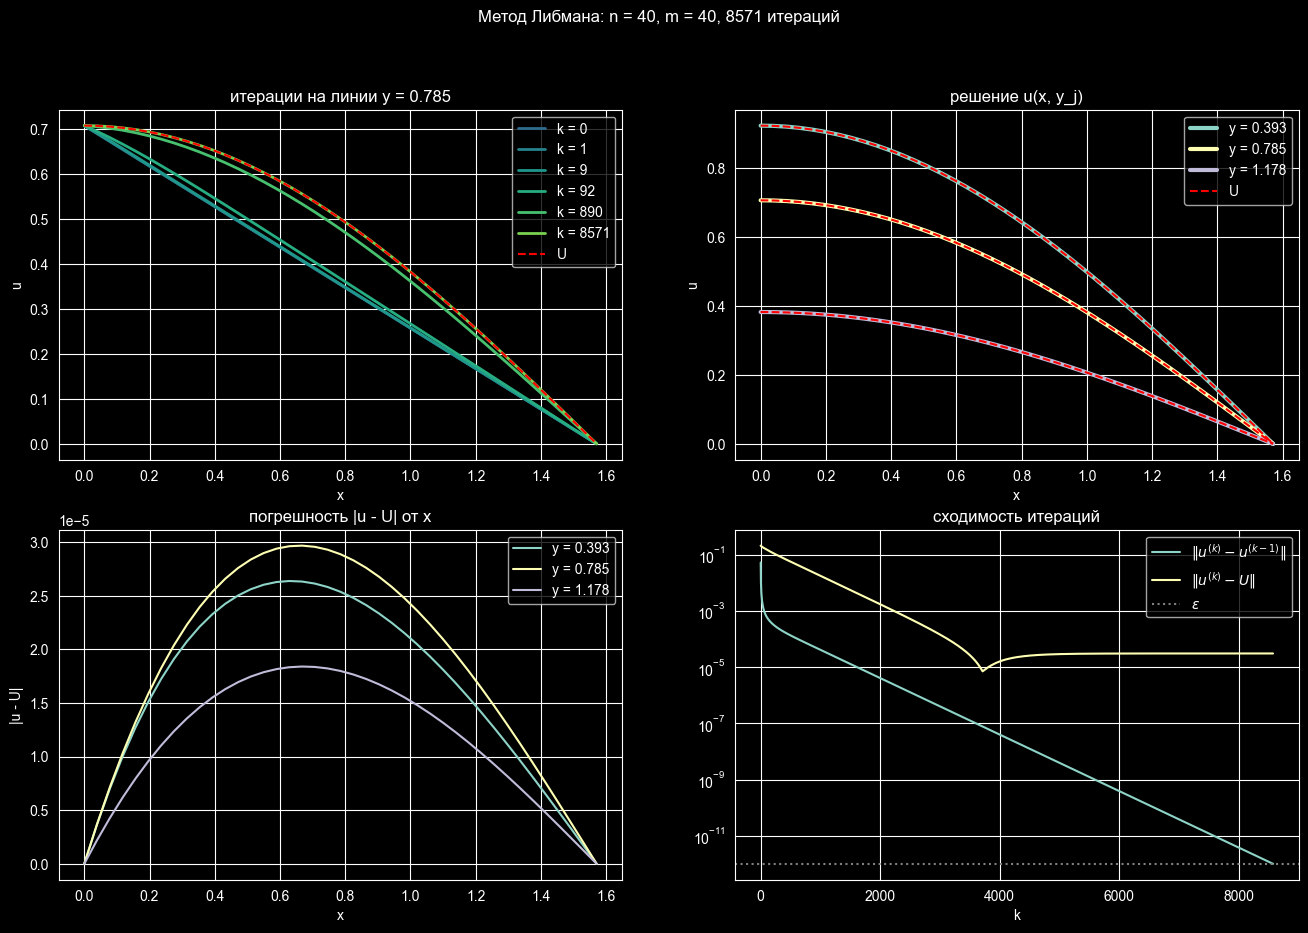

In [9]:
liebmann_result = liebmann(n, m)
plot_results(liebmann_result, 'Метод Либмана')

Погрешность $\|u^{(k)} - U\|$ сначала убывает вместе с разностью итераций, а затем выходит на постоянный уровень - погрешность самой разностной схемы $O(h_x^2 + h_y^2)$. Дальнейшие итерации уточняют решение разностной системы, но не приближают его к $U$.

Погрешность около $3 \cdot 10^{-5}$, она гладкая и обращается в ноль на границе, где значения заданы точно.

# 2. Метод Зейделя

При обходе узлов по возрастанию $i$ и $j$ к моменту пересчёта $u_{i,j}$ значения $u_{i-1,j}$ и $u_{i,j-1}$ уже найдены на текущей итерации. Метод Зейделя сразу их использует:

$
u^{(k+1)}_{i,j} = \alpha_1 u^{(k)}_{i+1,j} + \alpha_2 u^{(k+1)}_{i-1,j} + \alpha_3 u^{(k)}_{i,j+1} + \alpha_4 u^{(k+1)}_{i,j-1} + \beta_{i,j}.
$

Здесь узлы уже не независимы, и прямая запись - двойной цикл по $i$, $j$ на каждой итерации. Чтобы не делать $(n - 1)(m - 1)$ шагов цикла Python за итерацию, заметим: узел $(i, j)$ берёт новые значения с антидиагонали $i + j - 1$, а старые - с антидиагонали $i + j + 1$. Узлы одной антидиагонали $i + j = s$ друг от друга не зависят. Поэтому, пересчитывая антидиагонали по порядку $s = 2, 3, \ldots, n + m - 2$ (каждую целиком, векторно), получаем ровно те же значения, что и двойной цикл.

Для скорости нумеруем узлы одним индексом $p = i(m + 1) + j$ (так `numpy` хранит массив `u` в памяти); тогда соседи узла $p$ - это $p \pm (m + 1)$ по $x$ и $p \pm 1$ по $y$.

Сразу пишем функцию для метода верхней релаксации с параметром $\omega$: при $\omega = 1$ она и есть метод Зейделя.

In [10]:
def anti_diagonals(n, m):
    i, j = np.meshgrid(np.arange(1, n), np.arange(1, m), indexing='ij')
    return [(i[i + j == s], j[i + j == s]) for s in range(2, n + m - 1)]


def relaxation(n, m, omega, eps=eps, initial=interpolation_x, max_iterations=200_000):
    x, y, h_x, h_y = make_grid(n, m)
    s = make_stencil(x, y, h_x, h_y)
    beta = s.beta.reshape(-1)

    sweeps = []
    for i, j in anti_diagonals(n, m):
        p = i * (m + 1) + j
        sweeps.append((p, p + (m + 1), p - (m + 1), p + 1, p - 1, beta[p]))

    def step(u):
        u_flat = u.reshape(-1)  # вид на тот же массив, а не копия

        for p, right, left, up, down, beta_p in sweeps:
            seidel_value = (
                s.alpha_1 * u_flat[right] + s.alpha_2 * u_flat[left]
                + s.alpha_3 * u_flat[up] + s.alpha_4 * u_flat[down]
                + beta_p
            )
            u_flat[p] = omega * seidel_value + (1 - omega) * u_flat[p]

    return iterate(step, x, y, initial(x, y), eps, max_iterations)


seidel = partial(relaxation, omega=1)

Проверим, что обход по антидиагоналям даёт то же, что и обычный двойной цикл (5 итераций на сетке $7 \times 9$, $\omega = 1$ и $\omega = 1.5$):

In [11]:
def relaxation_by_loops(n, m, omega, iterations):
    x, y, h_x, h_y = make_grid(n, m)
    s = make_stencil(x, y, h_x, h_y)
    u = interpolation_x(x, y)

    for _ in range(iterations):
        for i in range(1, n):
            for j in range(1, m):
                seidel_value = (
                    s.alpha_1 * u[i + 1, j] + s.alpha_2 * u[i - 1, j]
                    + s.alpha_3 * u[i, j + 1] + s.alpha_4 * u[i, j - 1]
                    + s.beta[i, j]
                )
                u[i, j] = omega * seidel_value + (1 - omega) * u[i, j]

    return u


for omega in [1, 1.5]:
    by_loops = relaxation_by_loops(7, 9, omega, 5)
    by_diagonals = relaxation(7, 9, omega, eps=0, max_iterations=5).u
    print(f'omega = {omega}: max |разность| = {np.abs(by_loops - by_diagonals).max()}')

omega = 1: max |разность| = 0.0
omega = 1.5: max |разность| = 0.0


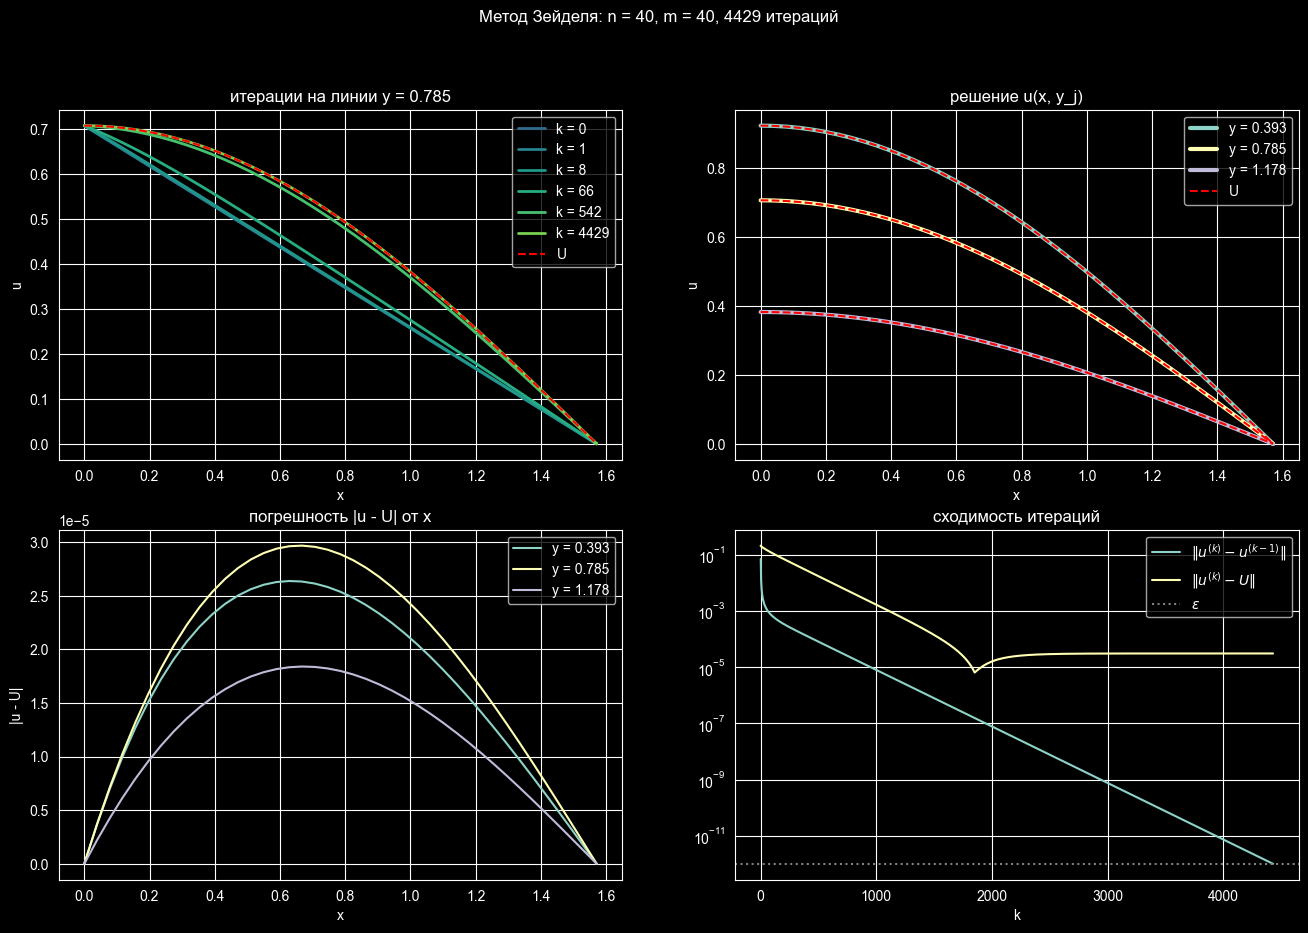

In [12]:
seidel_result = seidel(n, m)
plot_results(seidel_result, 'Метод Зейделя')

# 3. Метод простых итераций с верхней релаксацией

Новое значение - взвешенная сумма значения по Зейделю $\tilde u^{(k+1)}_{i,j}$ и значения с предыдущей итерации:

$
\tilde u^{(k+1)}_{i,j} = \alpha_1 u^{(k)}_{i+1,j} + \alpha_2 u^{(k+1)}_{i-1,j} + \alpha_3 u^{(k)}_{i,j+1} + \alpha_4 u^{(k+1)}_{i,j-1} + \beta_{i,j},
\qquad
u^{(k+1)}_{i,j} = \omega\,\tilde u^{(k+1)}_{i,j} + (1 - \omega)\,u^{(k)}_{i,j}.
$

При $\omega = 1$ это метод Зейделя, при $\omega < 1$ - нижняя релаксация, при $1 < \omega < 2$ - верхняя. Существует оптимальное значение $\omega^*$, при котором итераций меньше всего; его подбираем экспериментально.

Посмотрим, как число итераций зависит от $\omega$ на нескольких сетках:

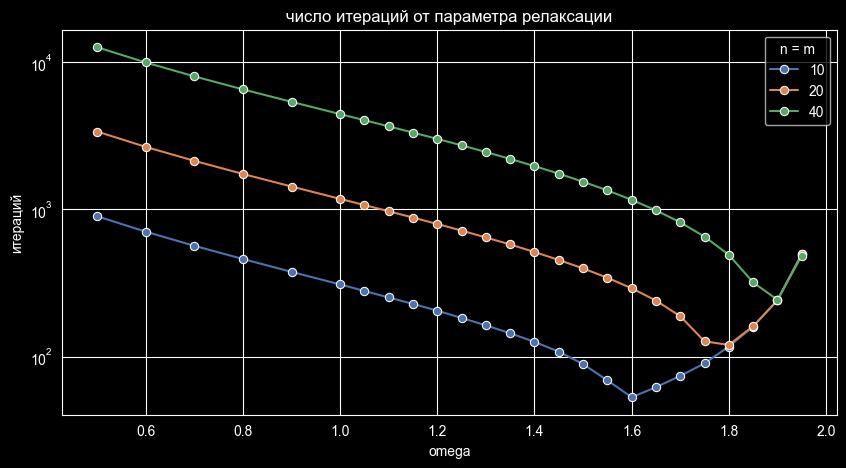

In [13]:
omegas = [0.5, 0.6, 0.7, 0.8, 0.9] + list(np.round(np.arange(1.0, 1.96, 0.05), 2))
omega_grids = [10, 20, 40]

omega_study = pd.DataFrame([
    {'n = m': k, 'omega': omega, 'итераций': len(relaxation(k, k, omega).diffs)}
    for k in omega_grids for omega in omegas
])

plt.figure(figsize=(10, 5))
ax = sns.lineplot(data=omega_study, x='omega', y='итераций', hue='n = m', marker='o', palette='deep')
ax.set_yscale('log')
ax.set_title('число итераций от параметра релаксации');

Число итераций сначала убывает, а после минимума растёт. С измельчением сетки минимум сдвигается к 2 и становится острее. При $\omega < 1$ (нижняя релаксация) итераций больше, чем у метода Зейделя ($\omega = 1$).

Раз зависимость такая, $\omega^*$ для любой сетки находим перебором сверху вниз: от $\omega = 1.95$ с шагом 0.05, пока число итераций не начнёт расти, затем уточняем с шагом 0.01 вокруг лучшего значения. Чтобы подбор был дешевле, итерации при подборе останавливаем уже при $\varepsilon = 10^{-6}$.

In [14]:
@cache
def best_omega(n, m, eps_search=1e-6):
    def iterations(omega):
        return len(relaxation(n, m, omega, eps=eps_search).diffs)

    best, best_iterations = None, None
    for omega in np.round(np.arange(1.95, 0.99, -0.05), 2):
        k = iterations(omega)
        if best is not None and k > best_iterations:
            break
        if best is None or k < best_iterations:
            best, best_iterations = omega, k

    for omega in np.round(np.arange(best - 0.04, best + 0.045, 0.01), 2):
        if omega != best and omega < 2:
            k = iterations(omega)
            if k < best_iterations:
                best, best_iterations = omega, k

    return float(best)


def sor(n, m, **kwargs):
    return relaxation(n, m, best_omega(n, m), **kwargs)


omega_summary = {}

for k in omega_grids:
    iterations = omega_study[omega_study['n = m'] == k].set_index('omega')['итераций']
    omega_summary[k] = {
        'лучшее omega (шаг 0.05)': iterations.idxmin(),
        'omega* (подбор)': best_omega(k, k),
        'итераций при omega = 1': iterations[1.0],
        'итераций при лучшем omega (шаг 0.05)': iterations.min(),
        'итераций при omega*': len(sor(k, k).diffs),
    }

pd.DataFrame(omega_summary).T.rename_axis('n = m')

,лучшее omega (шаг 0.05),omega* (подбор),итераций при omega = 1,итераций при лучшем omega (шаг 0.05),итераций при omega*
n = m,,,,,
10,1.6,1.59,309.0,53.0,52.0
20,1.8,1.77,1177.0,120.0,102.0
40,1.9,1.88,4429.0,243.0,203.0


Подобранное $\omega^*$ совпадает с минимумом на графике с точностью до шага перебора, а итераций при нём даже меньше, чем при лучшем $\omega$ из перебора с шагом 0.05: на сетке $40 \times 40$ - 203 против 243 (и 4429 у метода Зейделя).

omega* = 1.88


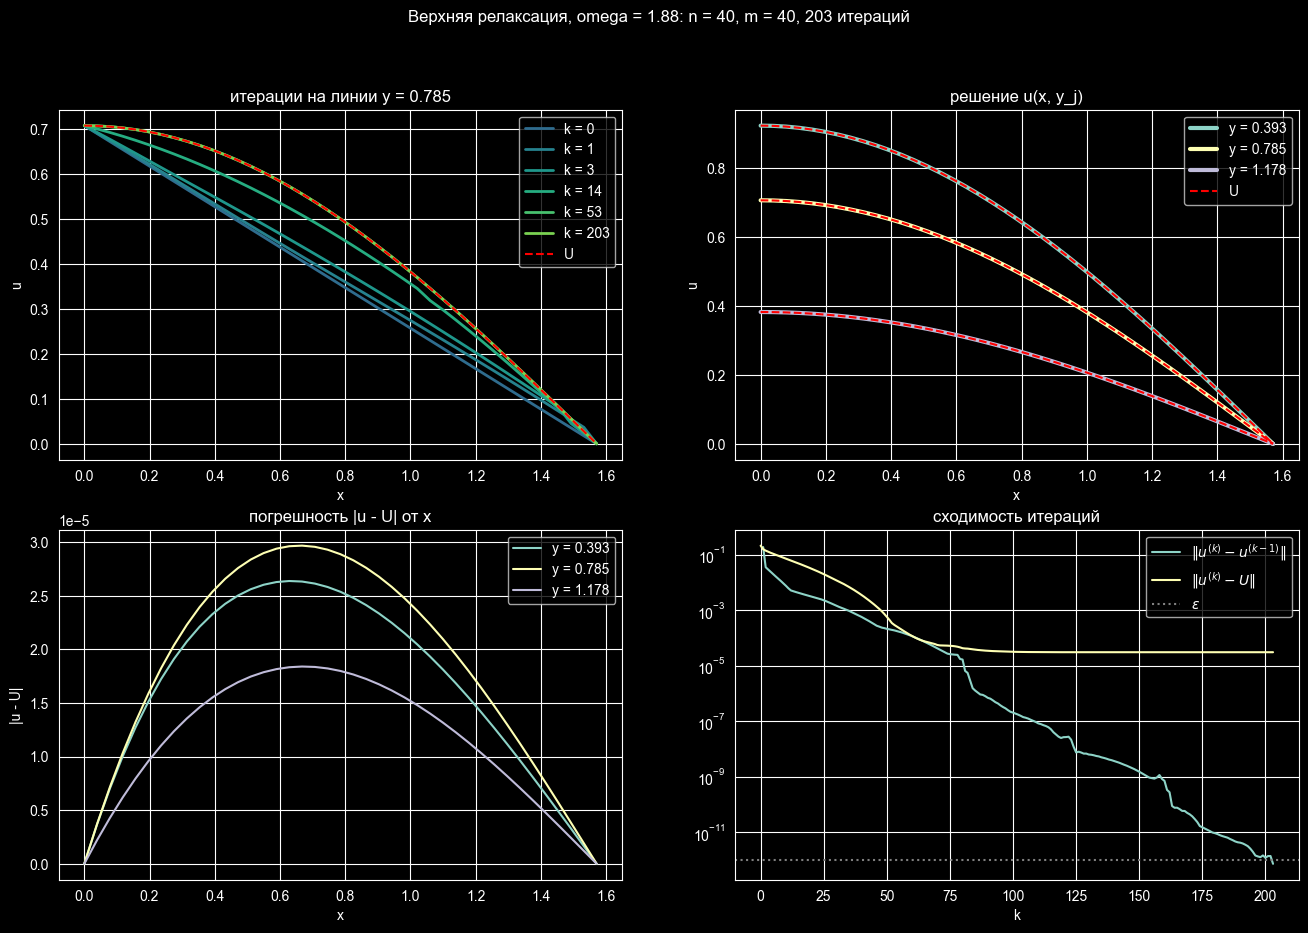

In [15]:
print(f'omega* = {best_omega(n, m)}')

sor_result = sor(n, m)
plot_results(sor_result, f'Верхняя релаксация, omega = {best_omega(n, m)}')

# 4. Сравнение методов

In [16]:
methods = {'Либман': liebmann, 'Зейдель': seidel, 'верхняя релаксация': sor}
results = {'Либман': liebmann_result, 'Зейдель': seidel_result, 'верхняя релаксация': sor_result}


def convergence_factor(diffs, last=10):
    return (diffs[-1] / diffs[-1 - last]) ** (1 / last)


pd.DataFrame({
    name: {
        'итераций': len(r.diffs),
        'погрешность': error(r.x, r.y, r.u),
        'множитель q': convergence_factor(r.diffs),
    }
    for name, r in results.items()
}).T

,итераций,погрешность,множитель q
Либман,8571.0,0.000031,0.997685
Зейдель,4429.0,0.000031,0.995376
верхняя релаксация,203.0,0.000031,0.863760


$q$ - во сколько раз в среднем уменьшается разность соседних итераций за одну итерацию (по последним 10 итерациям). У метода Зейделя $q$ равен квадрату $q$ метода Либмана ($0.99769^2 \approx 0.99538$), поэтому итераций ровно вдвое меньше. У верхней релаксации $q \approx 0.86$, и итераций на этой сетке в 42 раза меньше, чем у метода Либмана.

Все три метода решают одну и ту же разностную систему, поэтому их решения должны совпадать с точностью до критерия остановки:

In [17]:
names = list(results)
pd.DataFrame(
    [[np.abs(results[p].u - results[q].u).max() for q in names] for p in names],
    index=names, columns=names,
)

,Либман,Зейдель,верхняя релаксация
Либман,0.000000e+00,2.155780e-10,4.315841e-10
Зейдель,2.155780e-10,0.000000e+00,2.160061e-10
верхняя релаксация,4.315841e-10,2.160061e-10,0.000000e+00


Решения совпадают с точностью $4 \cdot 10^{-10}$ - это остаточная ошибка итераций при $\varepsilon = 10^{-12}$, она на пять порядков меньше погрешности схемы.

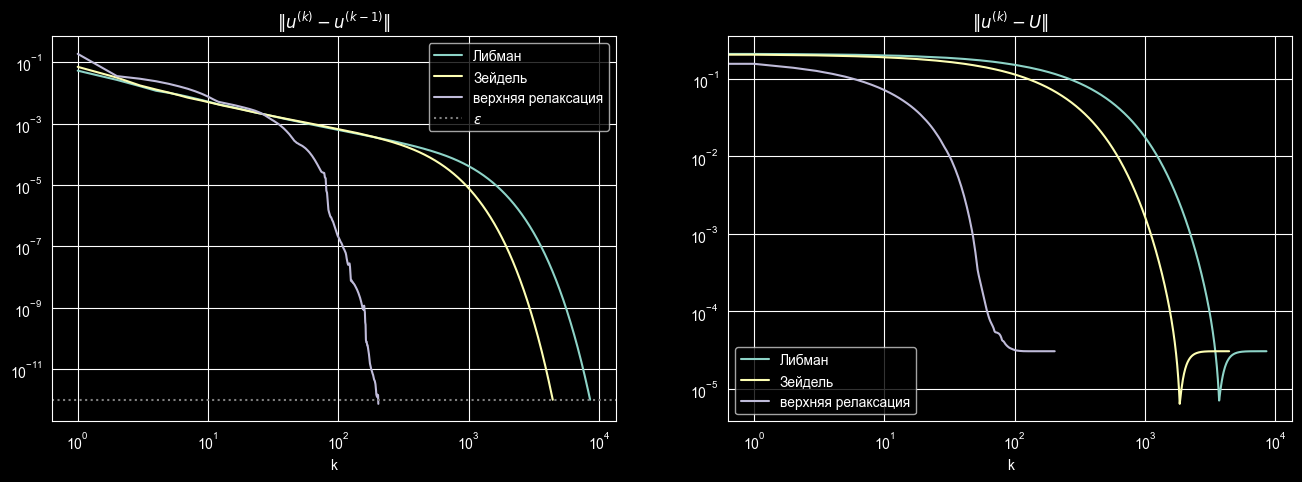

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for name, r in results.items():
    axes[0].plot(np.arange(1, len(r.diffs) + 1), r.diffs, label=name)
    axes[1].plot(np.arange(len(r.errors)), r.errors, label=name)

axes[0].axhline(eps, color='gray', linestyle=':', label=r'$\varepsilon$')
axes[0].set(title=r'$\|u^{(k)} - u^{(k-1)}\|$', xlabel='k')
axes[1].set(title=r'$\|u^{(k)} - U\|$', xlabel='k')

for ax in axes:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend()

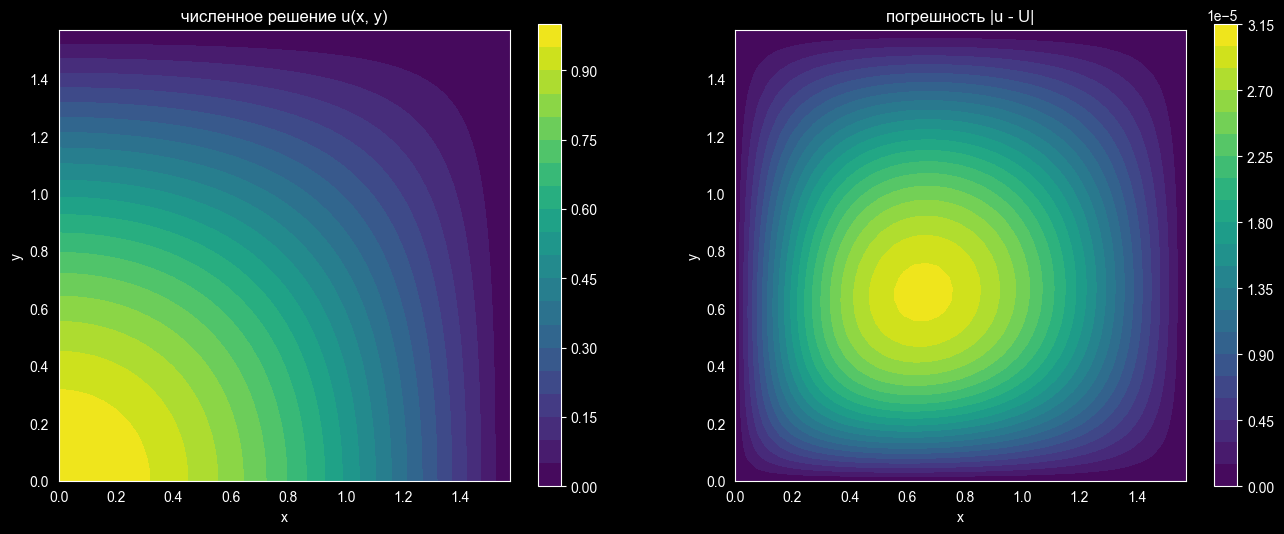

In [19]:
x_, y_, u_ = sor_result.x, sor_result.y, sor_result.u

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fields = [(u_, 'численное решение u(x, y)'), (np.abs(u_ - u_exact(x_[:, None], y_[None, :])), 'погрешность |u - U|')]

for ax, (values, title) in zip(axes, fields):
    contour = ax.contourf(x_, y_, values.T, levels=20, cmap='viridis')
    fig.colorbar(contour, ax=ax)
    ax.set(title=title, xlabel='x', ylabel='y', aspect='equal')

## Начальное приближение

Число итераций при трёх вариантах начального приближения:

In [20]:
initials = {'по x': interpolation_x, 'по y': interpolation_y, 'по x и y': interpolation_xy}

pd.DataFrame({
    initial_name: {name: len(method(n, m, initial=initial).diffs) for name, method in methods.items()}
    for initial_name, initial in initials.items()
})

,по x,по y,по x и y
Либман,8571,8571,8571
Зейдель,4429,4429,4429
верхняя релаксация,203,203,196


Интерполяции по $x$ и по $y$ дают одинаковое число итераций: задача симметрична относительно замены $x \leftrightarrow y$. Среднее двух интерполяций немного ускоряет только верхнюю релаксацию (196 итераций вместо 203). Скорость сходимости от начального приближения не зависит, поэтому выбор варианта почти не влияет на число итераций.

## Выбор $\varepsilon$

Критерий $\|u^{(k+1)} - u^{(k)}\| \le \varepsilon$ ограничивает только разность соседних итераций, а не расстояние до решения разностной системы. Когда итерации сходятся медленно ($q$ близко к 1), за одну итерацию решение меняется мало, хотя до решения ещё далеко, и разность соседних итераций оказывается намного меньше настоящей ошибки.

Итерации детерминированы, так что по уже сохранённым историям найдём, на какой итерации остановился бы каждый метод при разных $\varepsilon$ и какой была бы погрешность:

In [21]:
def stopping_table(results, eps_list):
    rows = []

    for name, r in results.items():
        diffs = np.array(r.diffs)

        for e in eps_list:
            k = np.argmax(diffs <= e) + 1
            rows.append({'метод': name, 'eps': e, 'итераций': k, 'погрешность': r.errors[k]})

    return pd.DataFrame(rows).pivot_table(index='eps', columns='метод', values=['итераций', 'погрешность'], sort=False)


stopping_table(results, [1e-2, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12])

итераций                            погрешность            \
метод          Либман Зейдель верхняя релаксация      Либман   Зейдель   
eps                                                                      
1.000000e-02      6.0     6.0                9.0    0.204392  0.195793   
1.000000e-04    621.0   453.0               62.0    0.042725  0.021425   
1.000000e-06   2606.0  1447.0               87.0    0.000402  0.000186   
1.000000e-08   4594.0  2441.0              125.0    0.000027  0.000029   
1.000000e-10   6583.0  3435.0              163.0    0.000031  0.000031   
1.000000e-12   8571.0  4429.0              203.0    0.000031  0.000031   

                                 
метод        верхняя релаксация  
eps                              
1.000000e-02           0.077451  
1.000000e-04           0.000095  
1.000000e-06           0.000036  
1.000000e-08           0.000031  
1.000000e-10           0.000031  
1.000000e-12           0.000031

При $\varepsilon = 10^{-4}$ погрешность метода Либмана $4.3 \cdot 10^{-2}$ - в 1400 раз больше погрешности схемы $3.1 \cdot 10^{-5}$, а при $\varepsilon = 10^{-2}$ итерации останавливаются уже на 6-м шаге. У верхней релаксации $q$ далеко от 1, и при $\varepsilon = 10^{-6}$ её погрешность $3.6 \cdot 10^{-5}$ уже близка к погрешности схемы.

При $\varepsilon = 10^{-8}$ погрешность метода Либмана даже чуть меньше итоговой: ошибка итераций случайно частично компенсирует погрешность схемы. Полагаться на такое совпадение нельзя. Начиная с $\varepsilon = 10^{-10}$ погрешность всех трёх методов определяется только схемой.

# 5. Зависимость погрешности от $h_x$ и $h_y$

## Одинаковые шаги $h_x = h_y = h$

Измельчаем сетку вдвое. По теореме о сходимости схема, которая аппроксимирует задачу с порядком $q$ и устойчива, сходится с тем же порядком, то есть $\varepsilon \approx Ch^q$. Тогда $\varepsilon(2h)/\varepsilon(h) = 2^q$, и наблюдаемый порядок $q = \log_2\dfrac{\varepsilon(2h)}{\varepsilon(h)}$.

In [22]:
def grid_study(methods, grids):
    rows = []

    for name, method in methods.items():
        prev_error = None

        for n_, m_ in grids:
            r = method(n_, m_)
            err = error(r.x, r.y, r.u)
            rows.append({
                'метод': name,
                'n': n_,
                'm': m_,
                'h_x': (R_x - L_x) / n_,
                'h_y': (R_y - L_y) / m_,
                'погрешность': err,
                'порядок': np.log2(prev_error / err) if prev_error else np.nan,
                'итераций': len(r.diffs),
            })
            prev_error = err

    return pd.DataFrame(rows)


def study_table(study, step, values=('погрешность', 'порядок')):
    return study.pivot_table(index='метод', columns=step, values=list(values), sort=False)


def plot_study(study, step, value, title, slopes):
    plt.figure(figsize=(8, 5))
    ax = sns.lineplot(data=study, x=step, y=value, hue='метод', style='метод', markers=True, dashes=False)

    for (name, slope), linestyle in zip(slopes.items(), [':', '--']):
        rows = study[study['метод'] == name]
        h = rows[step].to_numpy()
        ax.plot(h, rows[value].iloc[0] * (h / h[0]) ** slope, color='gray', linestyle=linestyle, label=f'~ h^{slope}')

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(title)
    ax.legend()


N_list = [5, 10, 20, 40, 80]

h_study = grid_study(methods, [(k, k) for k in N_list])
study_table(h_study, 'h_x')

погрешность                                          \
h_x                   0.314159  0.157080  0.078540  0.039270  0.019635   
метод                                                                    
Либман                0.001935  0.000487  0.000122  0.000031  0.000008   
Зейдель               0.001935  0.000487  0.000122  0.000031  0.000008   
верхняя релаксация    0.001935  0.000487  0.000122  0.000031  0.000008   

                     порядок                                
h_x                 0.157080  0.078540  0.039270  0.019635  
метод                                                       
Либман              1.989861  1.997258  1.996894  1.999404  
Зейдель             1.989861  1.997257  1.996885  1.999263  
верхняя релаксация  1.989861  1.997257  1.996875  1.999120

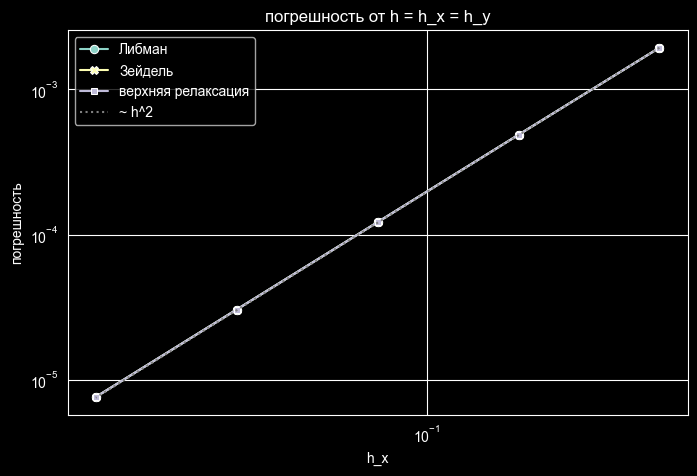

In [23]:
plot_study(h_study, 'h_x', 'погрешность', 'погрешность от h = h_x = h_y', slopes={'Либман': 2})

У всех трёх методов погрешности совпадают, а порядок равен 1.99–2.00 - подтверждается $O(h_x^2 + h_y^2)$.

Число итераций до $\|u^{(k+1)} - u^{(k)}\| \le \varepsilon$ на тех же сетках:

In [24]:
study_table(h_study, 'h_x', values=['итераций'])

итераций                                    
h_x                0.314159 0.157080 0.078540 0.039270 0.019635
метод                                                          
Либман                150.0    600.0   2285.0   8571.0  31915.0
Зейдель                78.0    309.0   1177.0   4429.0  16544.0
верхняя релаксация     27.0     52.0    102.0    203.0    405.0

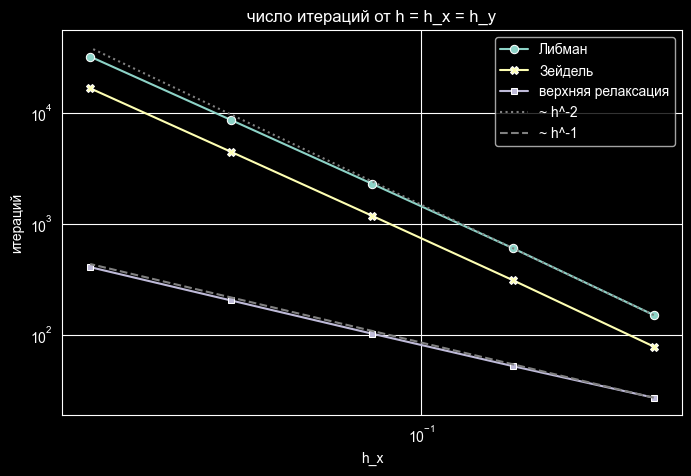

In [25]:
plot_study(h_study, 'h_x', 'итераций', 'число итераций от h = h_x = h_y', slopes={'Либман': -2, 'верхняя релаксация': -1})

При уменьшении $h$ вдвое число итераций методов Либмана и Зейделя растёт примерно вчетверо ($\sim h^{-2}$), а верхней релаксации с подобранным $\omega^*$ - примерно вдвое ($\sim h^{-1}$). На сетке $80 \times 80$ это 31915, 16544 и 405 итераций.

## Шаги по $x$ и по $y$ по отдельности

Погрешность не зависит от метода решения разностной системы (при достаточно малом $\varepsilon$). Поэтому здесь используем метод Либмана: у него нет параметра, который пришлось бы подбирать для каждой сетки. Считаем погрешность на всех сочетаниях $n$ и $m$ (строки - $n$, столбцы - $m$):

In [26]:
h_x_list = (R_x - L_x) / np.array(N_list)
h_y_list = (R_y - L_y) / np.array(N_list)

error_grid = pd.DataFrame(index=N_list, columns=N_list, dtype=float)

for n_ in N_list:
    for m_ in N_list:
        r = liebmann(n_, m_)
        error_grid.loc[n_, m_] = error(r.x, r.y, r.u)

error_grid.index.name = 'n'
error_grid.columns.name = 'm'
error_grid

m,5,10,20,40,80
n,,,,,
5,0.001935,0.001212,0.001031,0.000986,0.000975
10,0.001212,0.000487,0.000305,0.000259,0.000248
20,0.001031,0.000305,0.000122,0.000076,0.000065
40,0.000986,0.000259,0.000076,0.000031,0.000019
80,0.000975,0.000248,0.000065,0.000019,0.000008


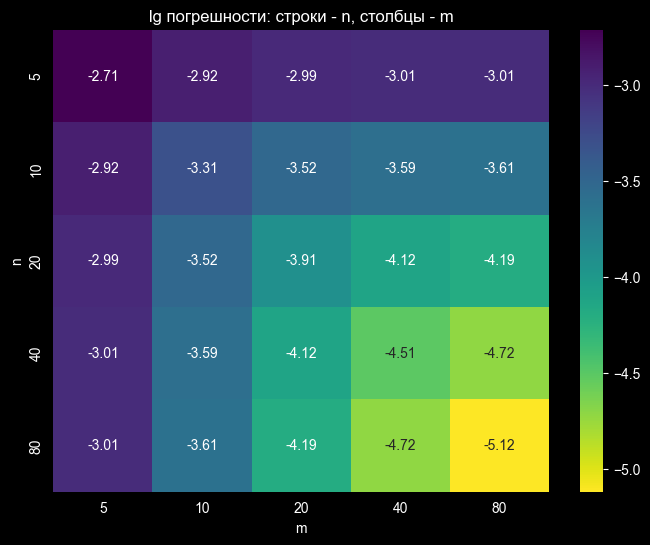

In [27]:
plt.figure(figsize=(8, 6))
ax = sns.heatmap(np.log10(error_grid), annot=True, fmt='.2f', cmap='viridis_r')
ax.set_title('lg погрешности: строки - n, столбцы - m');

Схема имеет погрешность аппроксимации $O(h_x^2 + h_y^2)$. Если и погрешность решения складывается из вкладов двух направлений, $\varepsilon \approx K(h_x^2 + h_y^2)$, то отношение $\varepsilon / (h_x^2 + h_y^2)$ должно быть примерно постоянным:

In [28]:
error_grid / (h_x_list[:, None]**2 + h_y_list[None, :]**2)

m,5,10,20,40,80
n,,,,,
5,0.009801,0.009826,0.009829,0.009838,0.009841
10,0.009826,0.009870,0.009877,0.009885,0.009889
20,0.009829,0.009877,0.009889,0.009897,0.009901
40,0.009838,0.009885,0.009897,0.009910,0.009912
80,0.009841,0.009889,0.009901,0.009912,0.009914


Отношение равно 0.0098–0.0099 на всех 25 сетках, то есть $\varepsilon \approx 0.0099\,(h_x^2 + h_y^2)$: погрешность складывается из независимых вкладов по $x$ и по $y$. Измельчать сетку только по одной переменной бесполезно - погрешность упирается во вклад другой. Например, при $n = 5$ она уменьшается с $1.9 \cdot 10^{-3}$ только до $9.8 \cdot 10^{-4}$, как бы ни росло $m$.

Из той же таблицы видна зависимость от каждого шага отдельно: столбец $m = 80$ - от $h_x$ при мелком $h_y$, строка $n = 80$ - от $h_y$ при мелком $h_x$. Если $\varepsilon \approx K(h_x^2 + h_y^2)$, то при фиксированном $h_y$ переход от $2h_x$ к $h_x$ уменьшает погрешность в $\dfrac{4h_x^2 + h_y^2}{h_x^2 + h_y^2}$ раз. Значит, ожидаемый порядок $\log_2\dfrac{4h_x^2 + h_y^2}{h_x^2 + h_y^2}$ близок к 2, пока $h_x \gg h_y$, и падает, когда $h_x$ сравнивается с $h_y$.

In [29]:
def one_direction(errors, steps, fixed_step):
    errors = np.asarray(errors, dtype=float)
    order = np.r_[np.nan, np.log2(errors[:-1] / errors[1:])]
    expected = np.r_[np.nan, np.log2((4 * steps[1:]**2 + fixed_step**2) / (steps[1:]**2 + fixed_step**2))]

    return pd.DataFrame(
        {'шаг': steps, 'погрешность': errors, 'порядок': order, 'ожидаемый порядок': expected},
        index=pd.Index(N_list, name='число шагов'),
    )


pd.concat({
    f'по h_x, m = {N_list[-1]}': one_direction(error_grid[N_list[-1]], h_x_list, h_y_list[-1]),
    f'по h_y, n = {N_list[-1]}': one_direction(error_grid.loc[N_list[-1]], h_y_list, h_x_list[-1]),
}, axis=1)

по h_x, m = 80                                          \
                       шаг погрешность   порядок ожидаемый порядок   
число шагов                                                          
5                 0.314159    0.000975       NaN               NaN   
10                0.157080    0.000248  1.976200          1.983257   
20                0.078540    0.000065  1.933123          1.934905   
40                0.039270    0.000019  1.763935          1.765535   
80                0.019635    0.000008  1.321637          1.321928   

            по h_y, n = 80                                          
                       шаг погрешность   порядок ожидаемый порядок  
число шагов                                                         
5                 0.314159    0.000975       NaN               NaN  
10                0.157080    0.000248  1.976199          1.983257  
20                0.078540    0.000065  1.933123          1.934905  
40                0.039270    0.000019  1.763935          1.765535  
80                0.019635    0.000008  1.321637          1.321928

Наблюдаемые порядки совпадают с ожидаемыми до сотых. Пока шаг по одной переменной намного больше шага по другой, порядок близок к 2, а на последнем шаге, когда $h_x = h_y$, он падает до 1.32. Зависимости от $h_x$ и от $h_y$ совпадают, потому что задача симметрична относительно замены $x \leftrightarrow y$.